# Université de Bordeaux, Master Informatique, parcours IA

## Reinforcement Learning

### Multi-armed Bandit Problem

The simplest setting for learning by trial and error.

Goal: understand the exploration/exploitation trade-off before moving to MDPs.

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

np.random.seed(42)
random.seed(42)

In [2]:
# Each arm has an unknown reward distribution.
# For teaching purposes, we store the true means to compute the regret.
class MultiArmedBandit:
    def __init__(self, number_of_arms: int) -> None:
        self.number_of_arms = number_of_arms
        
        # Each arm has an unknown mean reward mu_i in [0, 1].
        # In this notebook, rewards are Bernoulli:
        # r_i = 1 with probability mu_i, and 0 otherwise.
        self.means = np.random.uniform(0, 1, number_of_arms)
        
        # The optimal arm is the arm with the largest expected reward.
        # The agent does not know this; we keep it only for evaluation.
        self.optimal_arm = np.argmax(self.means)
        self.optimal_mean = self.means[self.optimal_arm]

    def play(self, arm: int) -> float:
        mean = self.means[arm]

        # Bernoulli reward: 1 with probability self.means[arm], 0 otherwise.
        return np.random.binomial(1, mean)
    


True means: [0.37 0.95 0.73 0.6  0.16 0.16 0.06 0.87 0.6  0.71]
Optimal arm: 1
Optimal mean: 0.95


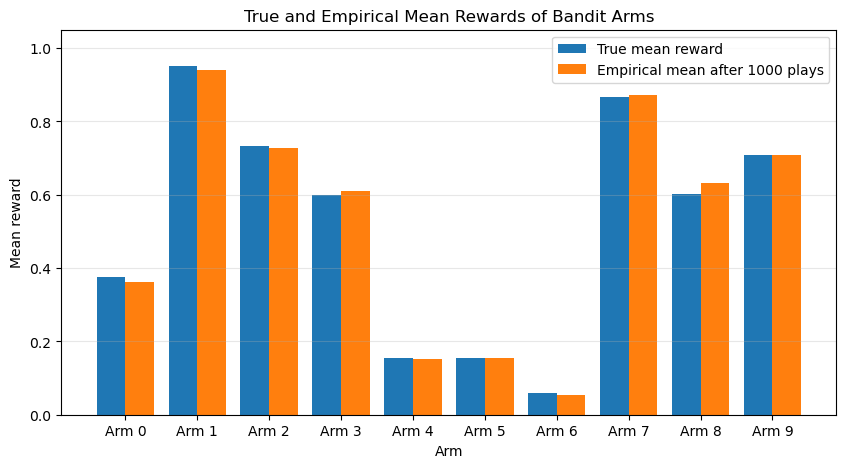

In [3]:
def plot_bandit(bandit: MultiArmedBandit, n_simulations: int = 1000) -> None:
    arms = np.arange(bandit.number_of_arms)
    rewards = []
    empirical_means = []
    for arm in range(bandit.number_of_arms):
        simulated_rewards = [bandit.play(arm) for _ in range(n_simulations)]
        rewards.append(simulated_rewards)
        empirical_means.append(np.mean(simulated_rewards))
    empirical_means = np.array(empirical_means)

    plt.figure(figsize=(10, 5))
    plt.bar(
        arms - 0.2,
        bandit.means,
        width=0.4,
        label="True mean reward"
    )
    plt.bar(
        arms + 0.2,
        empirical_means,
        width=0.4,
        label=f"Empirical mean after {n_simulations} plays"
    )
    plt.xlabel("Arm")
    plt.ylabel("Mean reward")
    plt.title("True and Empirical Mean Rewards of Bandit Arms")
    plt.xticks(arms, [f"Arm {i}" for i in arms])
    plt.ylim(0, 1.05)
    plt.grid(axis="y", alpha=0.3)
    plt.legend()
    plt.show()

bandit = MultiArmedBandit(number_of_arms=10)
print("True means:", np.round(bandit.means, 2))
print("Optimal arm:", bandit.optimal_arm)
print("Optimal mean:", round(bandit.optimal_mean, 2))
plot_bandit(bandit, n_simulations=1000)

In [4]:
def run_and_collect_data(agent, bandit, num_steps):
    rewards = []
    best_action_counts = []
    regrets = []
    for _ in range(num_steps):
        action = agent.choose_action()
        reward = bandit.play(action)
        rewards.append(reward)
        best_action_counts.append(action == bandit.optimal_arm)
        regrets.append(bandit.optimal_mean - bandit.means[action])
        agent.update(action, reward)
    return rewards, best_action_counts, regrets


In [5]:
# Function to run the bandit problem for multiple agents and plot the results
def run_and_plot_for_agents(agents, agent_names, bandit, num_steps):
    # Initialize storage for results
    all_rewards = []
    all_best_action_counts = []
    all_regrets = []

    # Run the simulation for each agent
    for agent in agents:
        rewards, best_action_counts, regrets = run_and_collect_data(agent, bandit, num_steps)
        all_rewards.append(rewards)
        all_best_action_counts.append(best_action_counts)
        all_regrets.append(regrets)
    
    # Calculate average results across all agents
    average_rewards = [np.cumsum(rewards) / (np.arange(len(rewards)) + 1) for rewards in all_rewards]
    average_best_action_counts = [np.cumsum(best_action_counts) / (np.arange(len(best_action_counts)) + 1) for best_action_counts in all_best_action_counts]
    cumulative_regrets = [np.cumsum(regrets) for regrets in all_regrets]
    
    # Plot the results
    fig, ax = plt.subplots(3, 1, figsize=(10, 12))
    
    for i, (agent, name) in enumerate(zip(agents, agent_names)):
        ax[0].plot(average_rewards[i], label=f'{name}')
        ax[1].plot(average_best_action_counts[i], label=f'{name}')
        ax[2].plot(cumulative_regrets[i], label=f'{name}')
    
    # Customize plots
    ax[0].set_xlabel('Steps', fontsize=12)
    ax[0].set_ylabel('Average Reward', fontsize=12)
    ax[0].set_title('Average Reward vs Steps', fontsize=14)
    ax[0].grid(linestyle='--', alpha=0.7)
    ax[0].legend()

    ax[1].set_xlabel('Steps', fontsize=12)
    ax[1].set_ylabel('Best Action Count', fontsize=12)
    ax[1].set_title('Best Action Count vs Steps', fontsize=14)
    ax[1].grid(linestyle='--', alpha=0.7)
    ax[1].legend()

    ax[2].set_xlabel('Steps', fontsize=12)
    ax[2].set_ylabel('Regret', fontsize=12)
    ax[2].set_title('Regret vs Steps', fontsize=14)
    ax[2].grid(linestyle='--', alpha=0.7)
    ax[2].legend()

    plt.tight_layout()
    plt.savefig('random.png')
    plt.show()


#### Random Agent

In [6]:
# Baseline agent: chooses an arm uniformly at random and does not learn.
class RandomAgent:
    def __init__(self, bandit: MultiArmedBandit) -> None:
        self.bandit = bandit
        self.number_of_arms = bandit.number_of_arms

    def choose_action(self) -> int:
        return random.randint(0, self.number_of_arms - 1)
    
    def update(self, arm: int, reward: float) -> None:
        pass
    

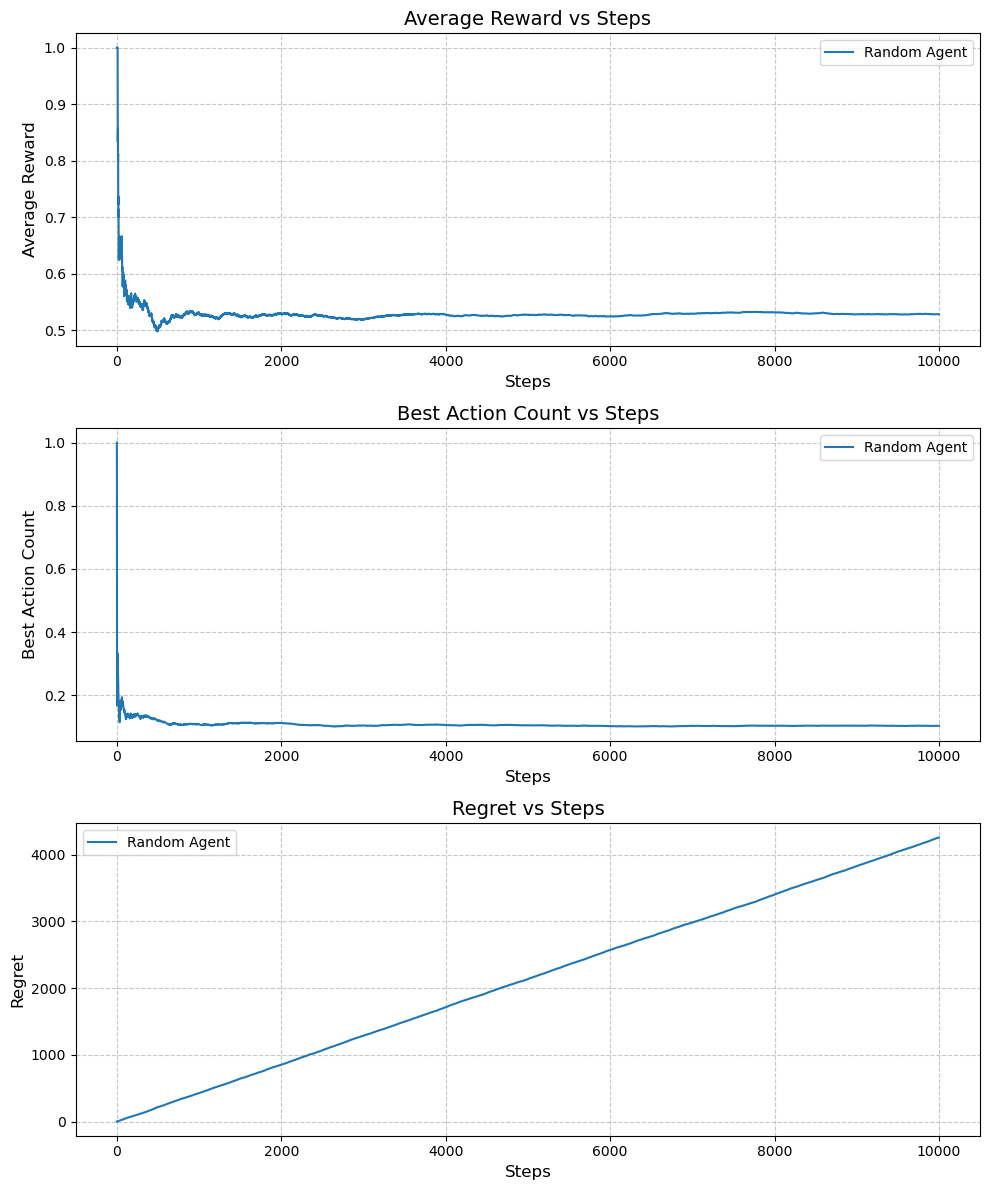

In [7]:
random_agent = RandomAgent(bandit)
agents = [random_agent]
agent_names = ['Random Agent']
run_and_plot_for_agents(agents, agent_names, bandit, 10000)

#### To conclude: 
The Random Agent is a baseline. It shows what happens when there is no learning: the average reward stabilizes, the optimal arm is selected approximately \(1/K\) of the time, and the cumulative regret grows linearly.

A good bandit algorithm should therefore perform better than this baseline: it should progressively select the optimal arm more often and slow down the growth of regret.

#### Explore-Then-Exploit

In [30]:
# An agent that explores every arm N times and then exploits the best estimated arm.
class ExploreThenExploit:
    def __init__(self, bandit: MultiArmedBandit, N: int) -> None:
        self.bandit = bandit
        self.number_of_arms = bandit.number_of_arms
        self.N = N
        self.action_count = np.zeros(self.number_of_arms)
        self.estimated_means = np.zeros(self.number_of_arms)
        self.stop_exploring = False

    def choose_action(self) -> int:
        if np.any(self.action_count < self.N):
            return np.argmin(self.action_count)
        else:
            self.stop_exploring = True
            return np.argmax(self.estimated_means)
        
    def update(self, arm: int, reward: float) -> None:
        self.action_count[arm] += 1
        self.estimated_means[arm] += (reward - self.estimated_means[arm]) / self.action_count[arm]
        


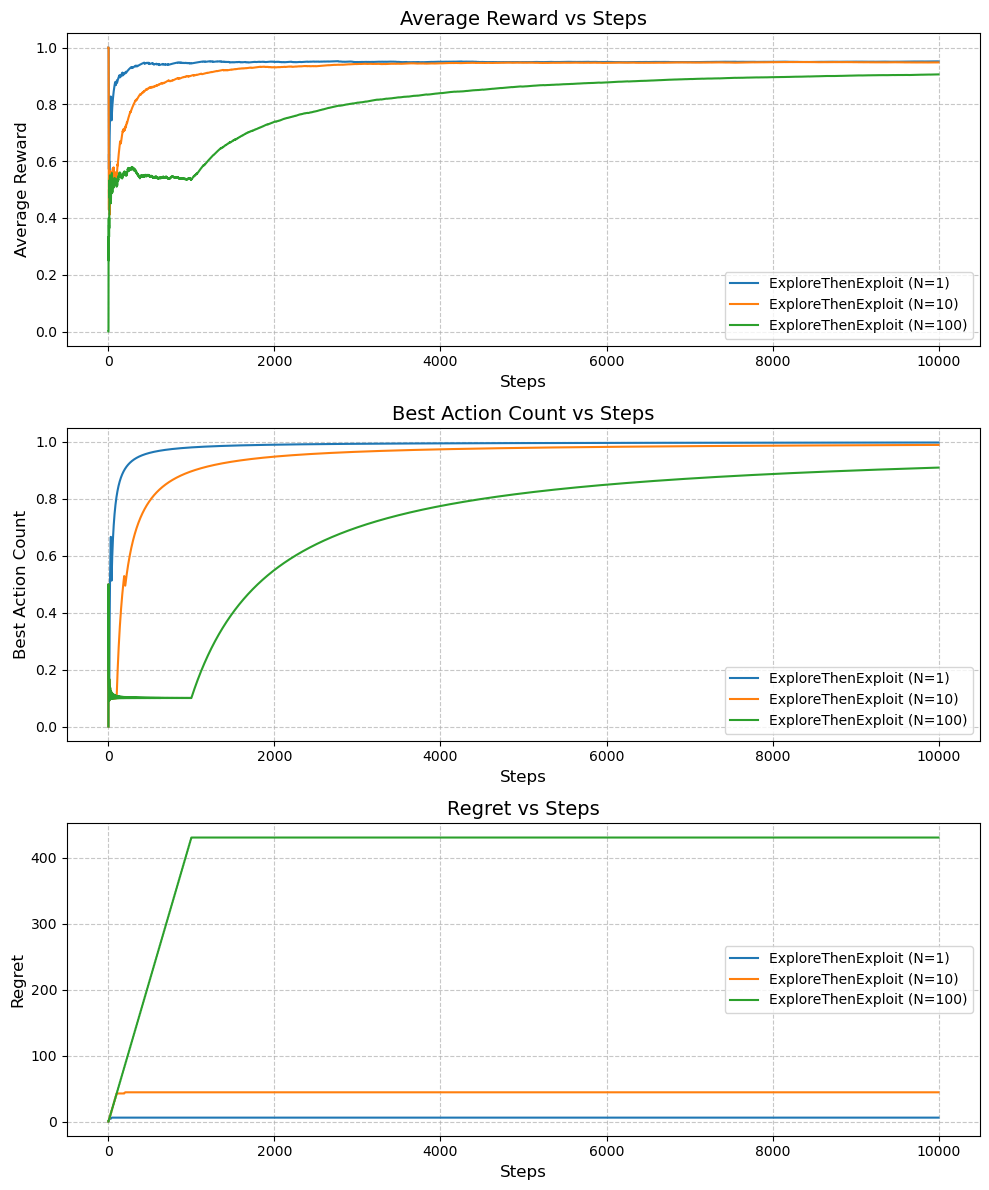

In [31]:
# run ExploreThenExploit agent for different values of N
agents = [ExploreThenExploit(bandit, N) for N in [1, 10, 100]]
agent_names = ['ExploreThenExploit (N=1)', 'ExploreThenExploit (N=10)', 'ExploreThenExploit (N=100)']
run_and_plot_for_agents(agents, agent_names, bandit, 10000)


What can you conclude?

#### Epsilon-Greedy

In [32]:
class EpsilonGreedy:
    def __init__(self, bandit: MultiArmedBandit, epsilon: float=0.1) -> None:
        self.bandit = bandit
        self.epsilon = epsilon
        self.number_of_arms = bandit.number_of_arms
        self.estimated_means = np.zeros(self.number_of_arms)
        self.action_counts = np.zeros(self.number_of_arms)

    def choose_action(self) -> int:
        if random.random() < self.epsilon:         #Exploration avec proba epsilon
            return random.randint(0, self.number_of_arms - 1)
        else:         #Exploitation avec proba 1-e
            return np.argmax(self.estimated_means)

    def update(self, action: int, reward: float) -> None:
        self.action_counts[action] += 1
        self.estimated_means[action] += (reward - self.estimated_means[action]) / self.action_counts[action]

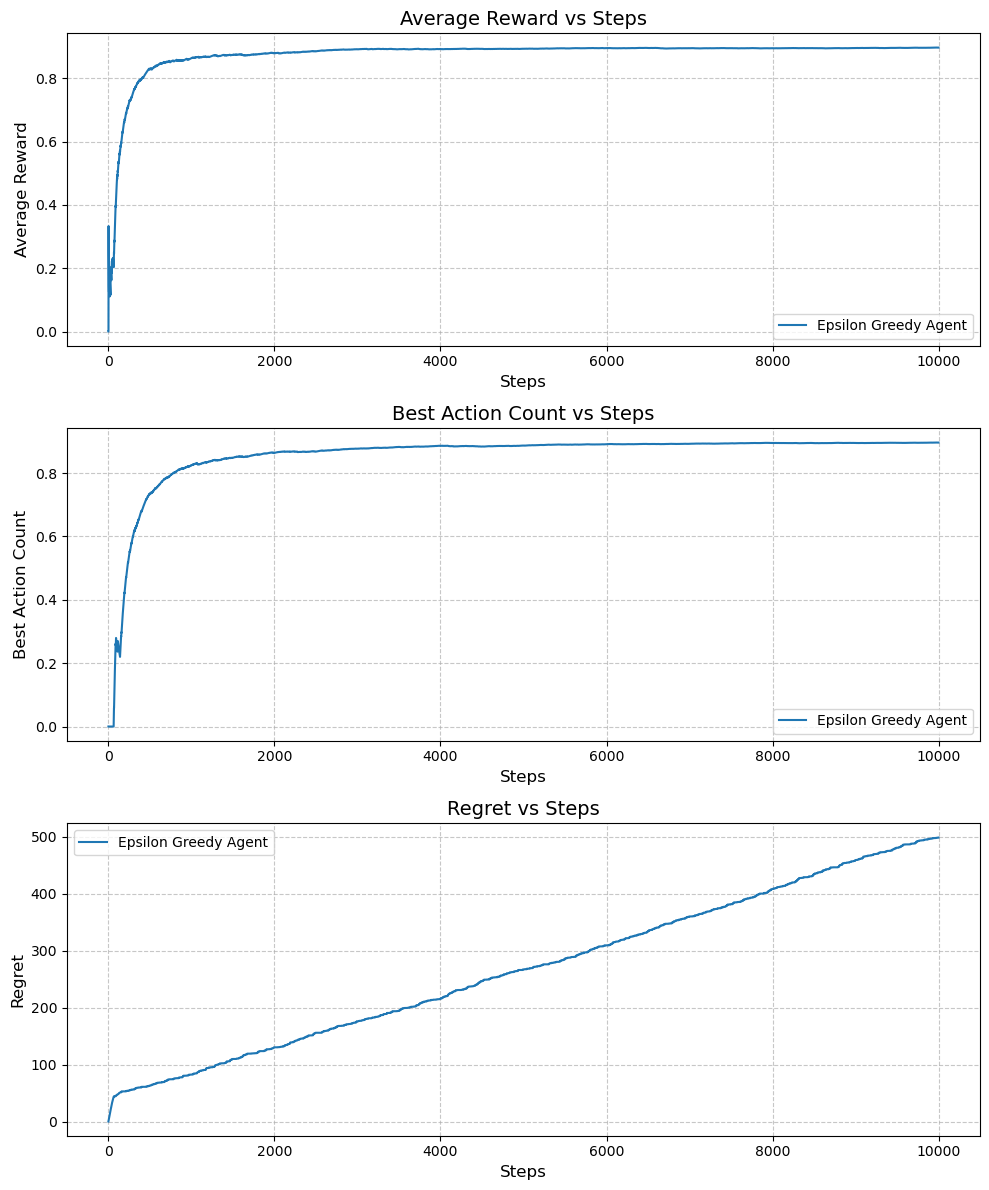

In [33]:
# Run the epsilon-greedy agent and plot the results
epsilon_greedy_agent = EpsilonGreedy(bandit, epsilon=0.1)
agents = [epsilon_greedy_agent]
agent_names = ['Epsilon Greedy Agent']
run_and_plot_for_agents(agents, agent_names, bandit, 10000)


##### Conclude.

#### Upper Confidence Bounds (UCB algorithm)

In [53]:
class UCB:
    def __init__(self, bandit: MultiArmedBandit, c: float=2) -> None:
        self.bandit = bandit
        self.c = c
        self.number_of_arms = bandit.number_of_arms
        self.estimated_means = np.zeros(self.number_of_arms)
        self.action_counts = np.zeros(self.number_of_arms)
        self.steps = 0
        pass

    def choose_action(self) -> int:
        self.steps += 1
        ucb_value = self.estimated_means + self.c*np.sqrt(np.log(self.steps)/(self.action_counts + 1e-5))
        return np.argmax(ucb_value)
        
    def update(self, action: int, reward: float) -> None:
        self.action_counts[action] += 1
        self.estimated_means[action] += (reward - self.estimated_means[action]) / self.action_counts[action]
        pass

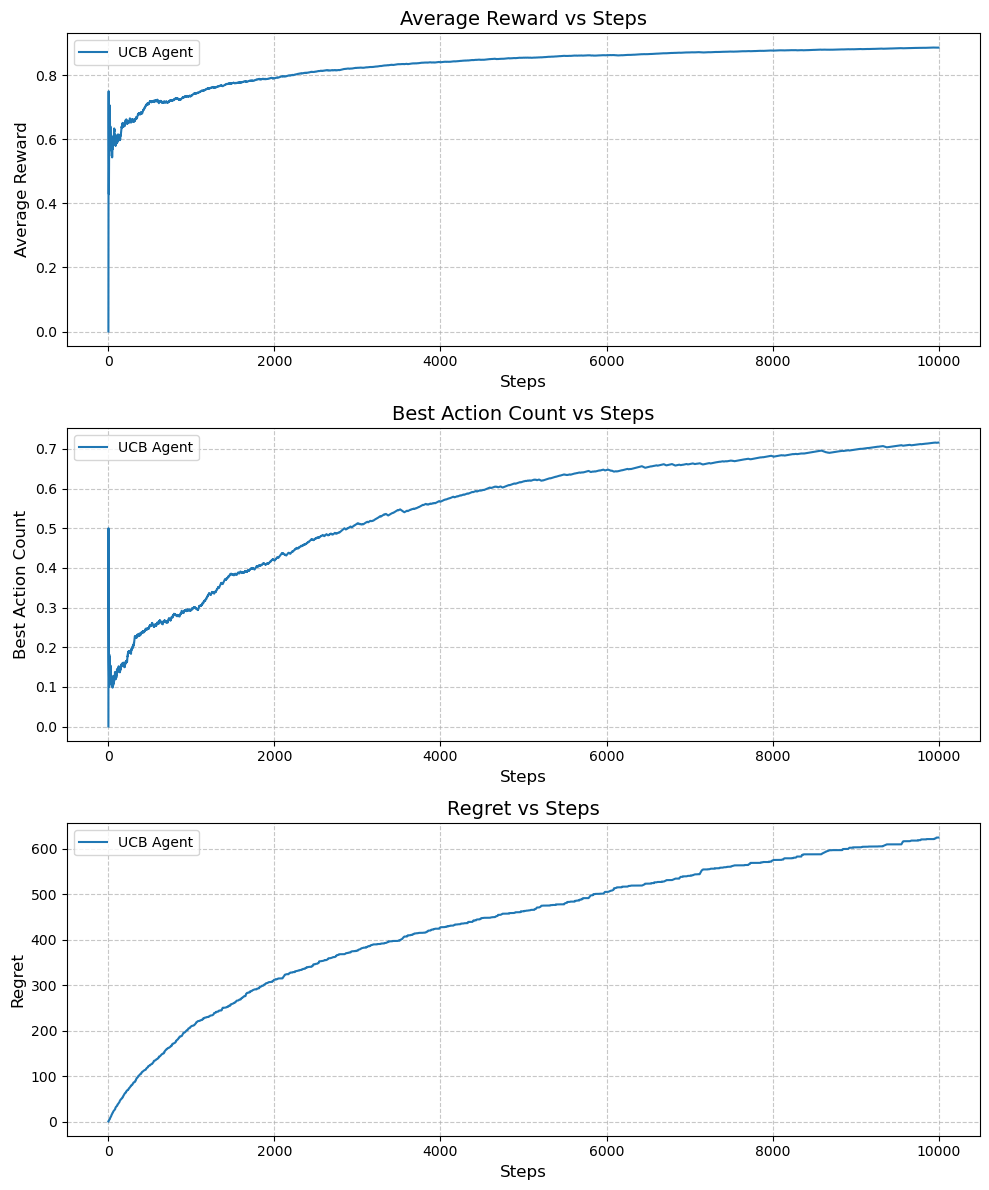

In [54]:
yucb_agent = UCB(bandit, c=2)
agents = [ucb_agent]
agent_names = ['UCB Agent']
run_and_pylot_for_agents(agents, agent_names, bandit, 10000)


##### Conclude.

#### Epsilon-greedy versus UCB

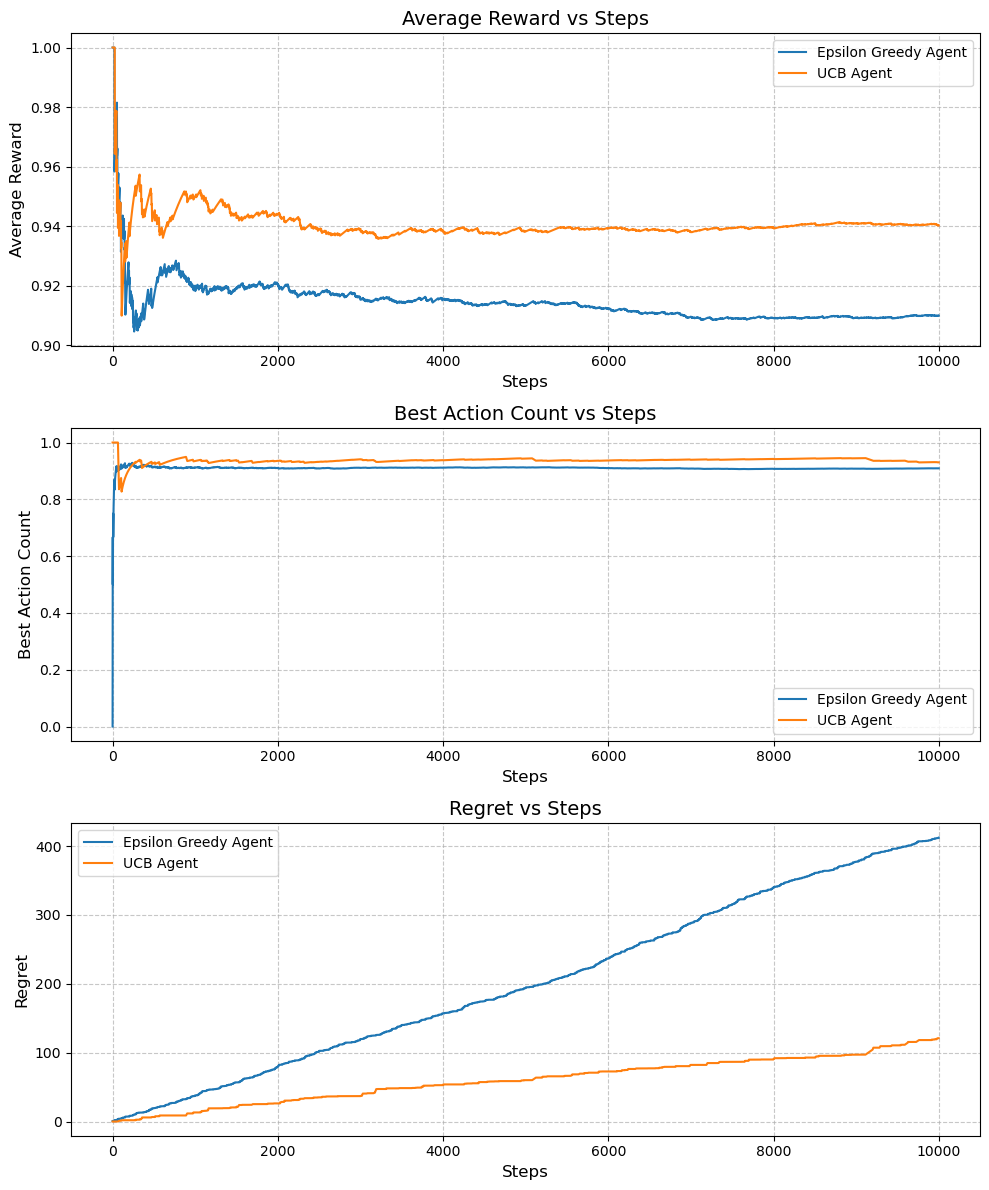

In [55]:
# run the epsilon greedy and UCB agents together
agents = [epsilon_greedy_agent, ucb_agent]
agent_names = ['Epsilon Greedy Agent', 'UCB Agent']
run_and_plot_for_agents(agents, agent_names, bandit, 10000)

##### Conclude. 

#### Influence of $\varepsilon$ in Epsilon-Greedy

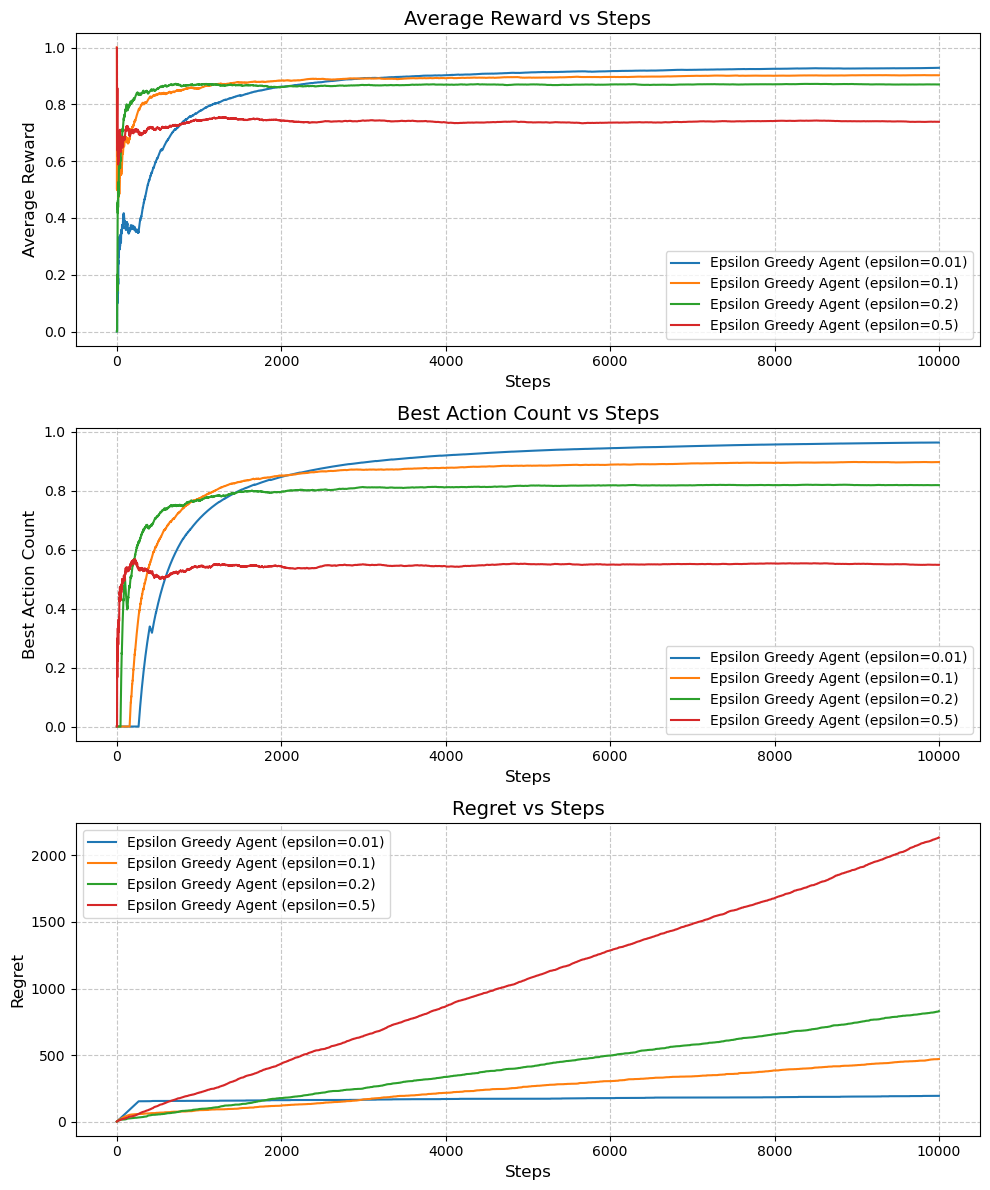

In [56]:
# run epsilon greedy for different values of epsilon
epsilons = [0.01, 0.1, 0.2, 0.5]
epsilon_agents = [EpsilonGreedy(bandit, epsilon) for epsilon in epsilons]
agent_names = [f'Epsilon Greedy Agent (epsilon={epsilon})' for epsilon in epsilons]
run_and_plot_for_agents(epsilon_agents, agent_names, bandit, 10000)

#### Influence of $c$ in UCB

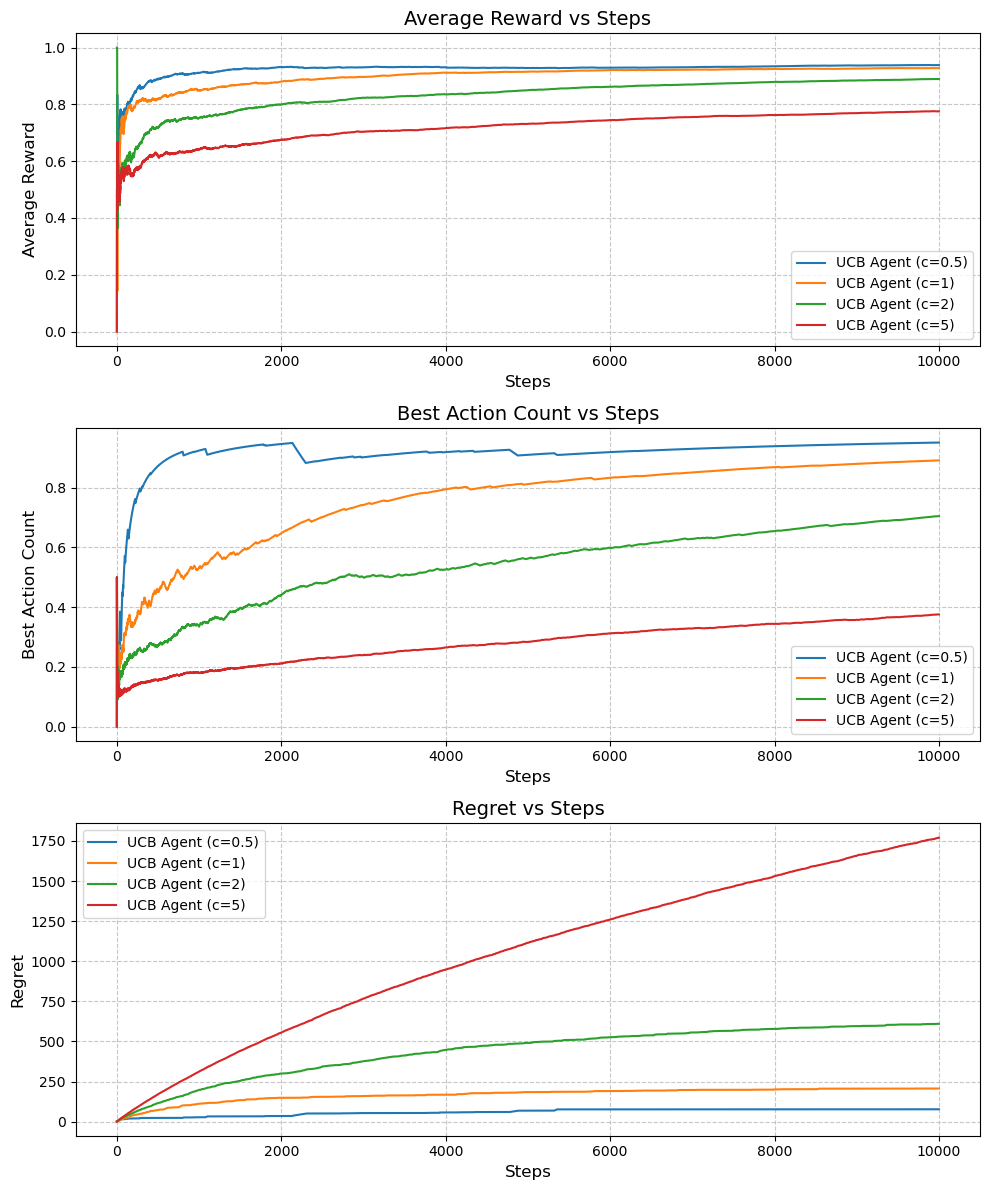

In [57]:
cs = [0.5, 1, 2, 5]
ucb_agents = [UCB(bandit, c) for c in cs]
agent_names = [f'UCB Agent (c={c})' for c in cs]
run_and_plot_for_agents(ucb_agents, agent_names, bandit, 10000)